# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 1 · Bài 2 (Trang 30): Tiền xử lý dữ liệu môi trường nhà xưởng (tb_tracking.xlsx)

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            **Dữ liệu:** `data/tb_tracking.xlsx` — dữ liệu đo môi trường, không có tiêu đề cột.

Câu 1 ↔ yêu cầu a, Câu 2 ↔ b, Câu 3 ↔ c, Câu 4 ↔ d.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: (a) Thêm tiêu đề các cột: id, device_id, co_level, humidity, temperature, time

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_excel(DATA + "tb_tracking.xlsx", header=None)
df.columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
print("Số dòng rỗng hoàn toàn (bị loại):", df.isnull().all(axis=1).sum())
df = df.dropna(how="all").reset_index(drop=True)
df[["id", "device_id"]] = df[["id", "device_id"]].astype(int)
print("Kích thước:", df.shape)
display(df.head(10))
df.info()
display(df.describe().round(2))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Số dòng rỗng hoàn toàn (bị loại): 1
Kích thước: (33339, 6)


,id,device_id,co_level,humidity,temperature,time
0,1,1,2.0,3.0,4.0,2016-12-20 12:52:29
1,2,1,2.0,3.0,4.0,2016-12-20 12:52:31
2,3,100,2.0,3.0,4.0,2016-12-20 12:52:35
3,4,100,2.0,3.0,400.0,2016-12-20 12:52:37
4,5,1,2.0,3.0,4.0,2016-12-20 13:02:01
5,6,100,2.0,3.0,400.0,2016-12-20 13:02:24
6,7,-1,0.0,83.0,28.0,2016-12-21 12:03:39
7,8,-1,0.0,83.0,28.0,2016-12-21 12:05:02
8,9,-1,0.0,83.0,28.0,2016-12-21 12:05:49
9,10,1,2.0,3.0,4.0,2016-12-21 12:08:58


<class 'pandas.DataFrame'>
RangeIndex: 33339 entries, 0 to 33338
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33339 non-null  int64         
 1   device_id    33339 non-null  int64         
 2   co_level     33339 non-null  float64       
 3   humidity     33339 non-null  float64       
 4   temperature  33339 non-null  float64       
 5   time         33339 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 1.5 MB


,id,device_id,co_level,humidity,temperature,time
count,33339.00,33339.00,33339.00,33339.00,33339.00,33339
mean,16668.50,97928.27,181.81,2127.77,138592.42,2017-03-15 07:00:52.219463
min,1.00,-1.00,0.00,0.00,0.00,2016-12-20 12:52:29
25%,8334.50,99001.00,33.00,32.00,10.00,2017-01-06 07:56:15
50%,16668.00,99005.00,43.00,54.00,87.00,2017-03-11 13:02:38
75%,25002.50,99005.00,76.00,92.00,10996.00,2017-04-25 07:14:53
max,33336.00,99005.00,4030.00,11030.00,5340310.00,2018-01-17 15:46:34
std,9623.85,10259.25,710.32,4301.63,561916.40,NaN


**Nhận xét:**

- File không có tiêu đề nên được gán 6 tên cột theo đúng thứ tự đề bài. Có **1 dòng rỗng hoàn toàn** được loại bỏ, còn lại 33 339 dòng.
- Dữ liệu đo từ 20/12/2016 đến 17/01/2018. `device_id` gồm nhiều giá trị lạ (−1, 0, 1, 100 …) bên cạnh 99001/99005, và các giá trị đo có cực trị bất thường (`temperature` lớn nhất 5 340 310, `humidity` 11 030). Điều này cho thấy giai đoạn đầu cảm biến chưa ổn định.

## Câu 2: (b) Chỉ giữ dữ liệu từ ngày 03/01/2018, loại bỏ dữ liệu trước đó

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
print("Thời gian đo: từ", df["time"].min(), "đến", df["time"].max())
print("Số dòng trước khi lọc:", len(df))
df = df[df["time"] >= "2018-01-03"].reset_index(drop=True)
print("Số dòng sau khi lọc  :", len(df))
print("Thời điểm đo sớm nhất còn lại:", df["time"].min())
display(df.head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Thời gian đo: từ 2016-12-20 12:52:29 đến 2018-01-17 15:46:34
Số dòng trước khi lọc: 33339
Số dòng sau khi lọc  : 1918
Thời điểm đo sớm nhất còn lại: 2018-01-03 13:11:07


,id,device_id,co_level,humidity,temperature,time
0,31420,1,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421,1,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422,99005,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423,99005,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424,99005,58.0,26.0,0.0,2018-01-03 13:24:17


**Nhận xét:**

- Chỉ giữ dữ liệu từ ngày **03/01/2018**: số dòng giảm từ 33 339 xuống **1 918** (khoảng 5.8%). Thời điểm sớm nhất còn lại là 2018-01-03 13:11:07.
- Hơn 94% dữ liệu là dữ liệu đo thử trong giai đoạn hiệu chỉnh cảm biến. Nếu giữ lại sẽ làm sai lệch mọi phân tích phía sau.

## Câu 3: (c) Bóc tách thời điểm đo trong ngày tính theo phút (minutes)

In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["minutes"] = df["time"].dt.hour * 60 + df["time"].dt.minute
display(df[["id", "time", "minutes"]].head(10))
print("minutes nằm trong khoảng:", df["minutes"].min(), "-", df["minutes"].max())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,id,time,minutes
0,31420,2018-01-03 13:11:07,791
1,31421,2018-01-03 13:15:10,795
2,31422,2018-01-03 13:17:30,797
3,31423,2018-01-03 13:19:21,799
4,31424,2018-01-03 13:24:17,804
5,31425,2018-01-03 13:29:13,809
6,31426,2018-01-03 13:34:10,814
7,31427,2018-01-03 14:05:34,845
8,31428,2018-01-03 14:10:43,850
9,31429,2018-01-03 14:15:39,855


minutes nằm trong khoảng: 1 - 1439


**Nhận xét:**

- `minutes = giờ × 60 + phút`, ví dụ 13:11:07 → 791. Giá trị nằm trong khoảng 1 – 1439, phủ kín cả ngày.
- Phần giây bị bỏ qua vì yêu cầu tính theo phút. Thuộc tính này cho phép gộp các ngày đo khác nhau lên cùng một trục thời gian trong ngày.

## Câu 4: (d) Vẽ đồ thị phân tán co_level, humidity, temperature theo minutes

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


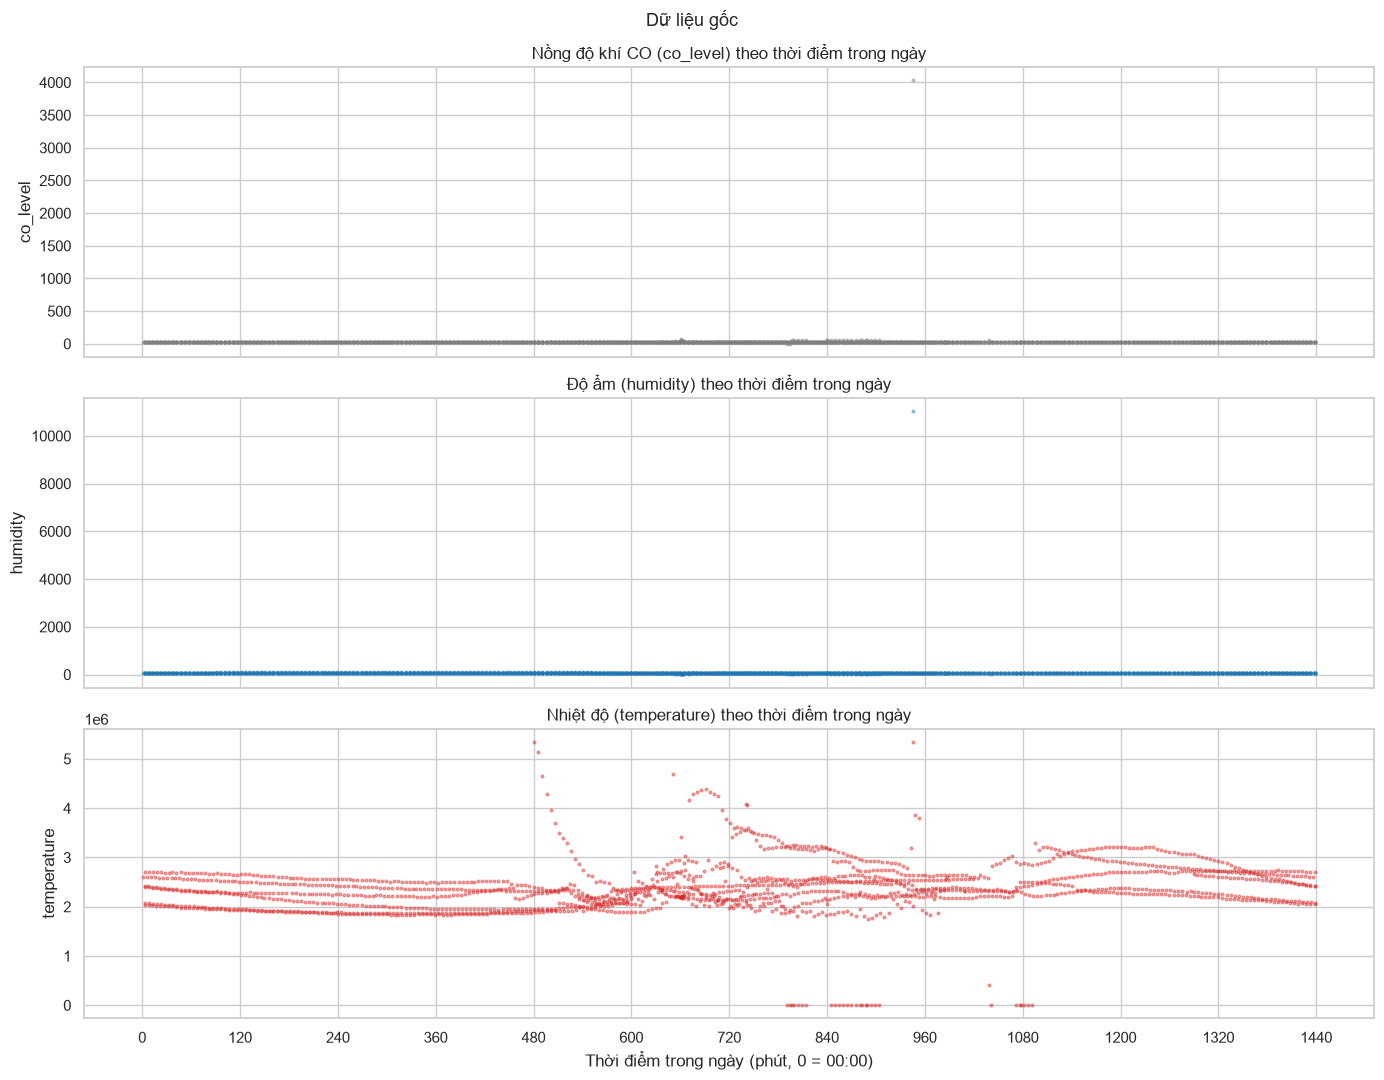

,co_level,humidity,temperature
count,1918.00,1918.00,1918.00
mean,30.28,74.71,2360519.51
std,91.46,250.57,499671.42
min,2.00,3.00,0.00
25%,27.00,61.00,2124662.50
50%,28.00,70.50,2331140.00
75%,28.00,79.00,2570745.00
max,4030.00,11030.00,5340310.00


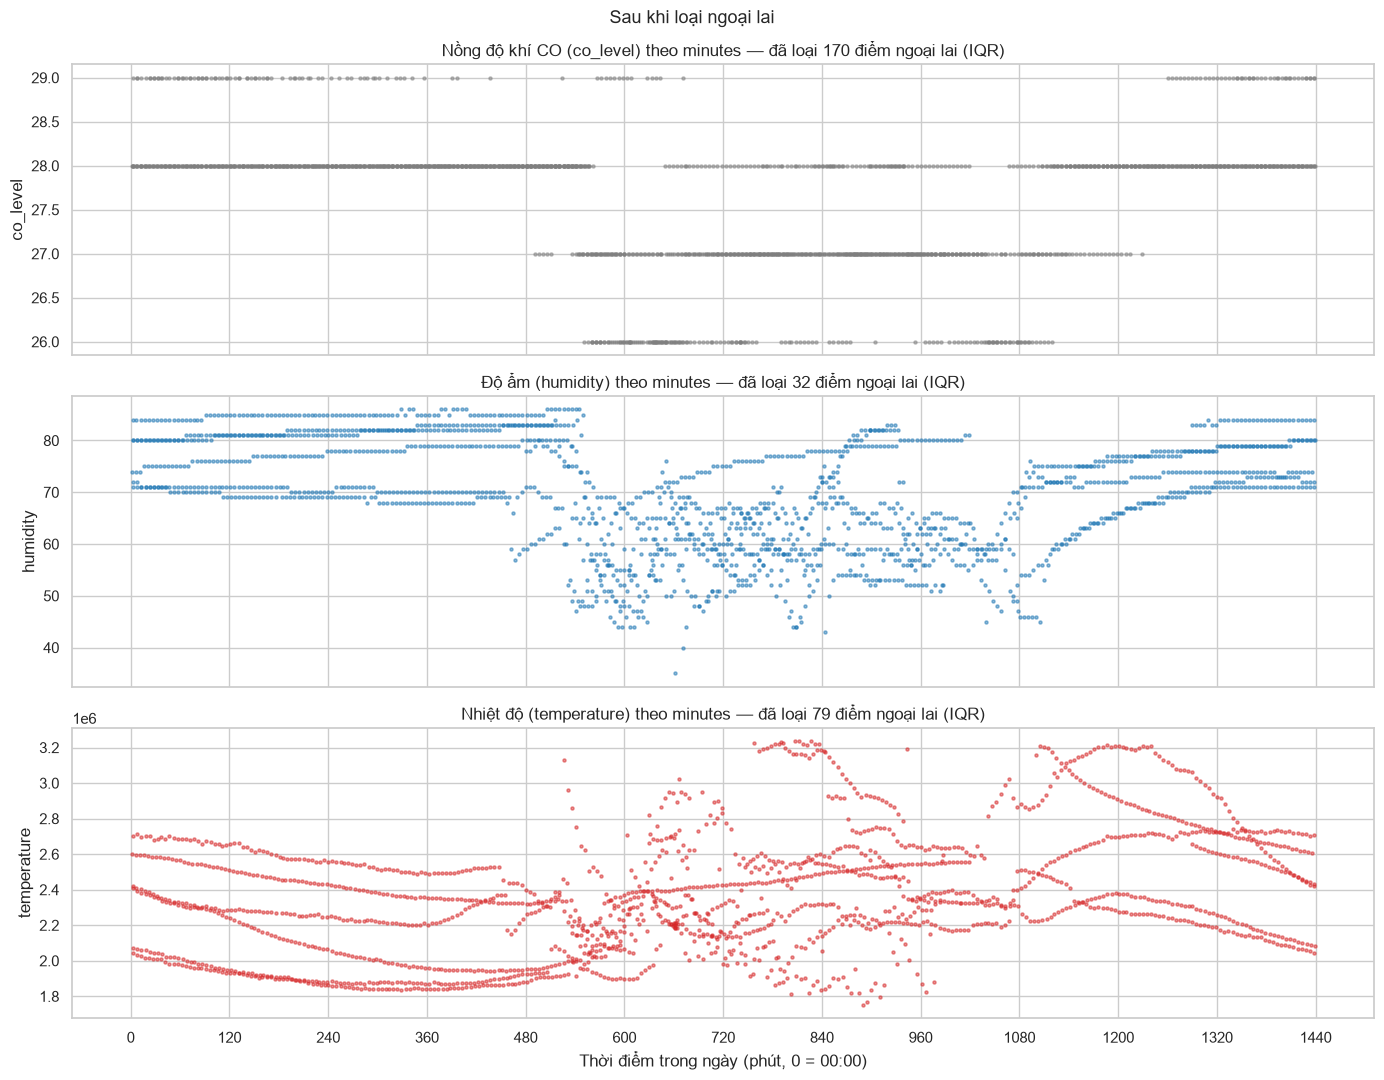

In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, col, ten, mau in zip(axes, ["co_level", "humidity", "temperature"],
                             ["Nồng độ khí CO", "Độ ẩm", "Nhiệt độ"], ["tab:gray", "tab:blue", "tab:red"]):
    ax.scatter(df["minutes"], df[col], s=4, alpha=0.4, color=mau)
    ax.set_title(f"{ten} ({col}) theo thời điểm trong ngày"); ax.set_ylabel(col)
axes[-1].set_xlabel("Thời điểm trong ngày (phút, 0 = 00:00)")
axes[-1].set_xticks(range(0, 1441, 120))
plt.suptitle("Dữ liệu gốc", fontsize=13); plt.tight_layout(); plt.show()
display(df[["co_level", "humidity", "temperature"]].describe().round(2))

# Các giá trị ngoại lai (VD co_level = 4030) làm "dẹt" đồ thị -> vẽ thêm bản đã loại ngoại lai theo IQR để dễ quan sát
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, col, ten, mau in zip(axes, ["co_level", "humidity", "temperature"],
                             ["Nồng độ khí CO", "Độ ẩm", "Nhiệt độ"], ["tab:gray", "tab:blue", "tab:red"]):
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    m = df[col].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    ax.scatter(df.loc[m, "minutes"], df.loc[m, col], s=5, alpha=0.5, color=mau)
    ax.set_title(f"{ten} ({col}) theo minutes — đã loại {(~m).sum()} điểm ngoại lai (IQR)"); ax.set_ylabel(col)
axes[-1].set_xlabel("Thời điểm trong ngày (phút, 0 = 00:00)")
axes[-1].set_xticks(range(0, 1441, 120))
plt.suptitle("Sau khi loại ngoại lai", fontsize=13); plt.tight_layout(); plt.show()

**Nhận xét:**

- Trên đồ thị dữ liệu gốc, vài điểm ngoại lai (`co_level` tới 4 030, `humidity` tới 11 030) làm các đồ thị bị "dẹt". Bộ đồ thị thứ hai đã loại ngoại lai theo IQR (170, 32 và 79 điểm) nên dễ quan sát hơn.
- **Độ ẩm**: ban đêm cao và ổn định (khoảng 70 – 86). Trong giờ làm việc (khoảng phút 540 – 1080, tức 9h – 18h) độ ẩm giảm xuống 45 – 70 và dao động mạnh, sau 18h tăng trở lại.
- **Nồng độ CO** chỉ nhận vài giá trị rời rạc 26 – 29. Ban ngày (9h – 18h) chủ yếu ở mức 26 – 27, ban đêm ở mức 28 – 29.
- **Nhiệt độ** có độ lớn khoảng 1.8 – 3.2 × 10⁶, rõ ràng không phải đơn vị °C (có thể là giá trị thô của cảm biến hoặc thứ tự cột trong file khác mô tả). Tuy vậy mỗi ngày tạo thành một đường cong trơn, giảm dần về đêm và biến động mạnh trong giờ làm việc. Cần xác minh lại đơn vị/thang đo trước khi dùng cho phân tích.